Final receptor-matched ROC cohort: 241 patients

Cohort summary
--------------
Patients: 241
Metastatic ER+: 182
Metastatic ER-: 59
Primary ER+: 199
Primary ER-: 42
TFx <3%: 9

Primary/metastatic concordance
metastatic_ER  Negative  Positive
Primary_ER                       
Negative             40         2
Positive             19       180

ER concordance summary
----------------------
Paired evaluable patients: 241
ER-concordant patients: 220
ER-discordant patients: 21

ER transition counts
primary_ER  metastatic_ER
Negative    Negative          40
            Positive           2
Positive    Negative          19
            Positive         180

ER-discordant patient details
patient_id   sample primary_ER metastatic_ER  earliest_met_diagnosis_day  selected_met_ER_day selected_met_ER_site  informative_met_ER_record_count
        11 ANFC-NB1   Positive      Negative                        1601               1601.0           lymph node                                2
   1101-14 API9-

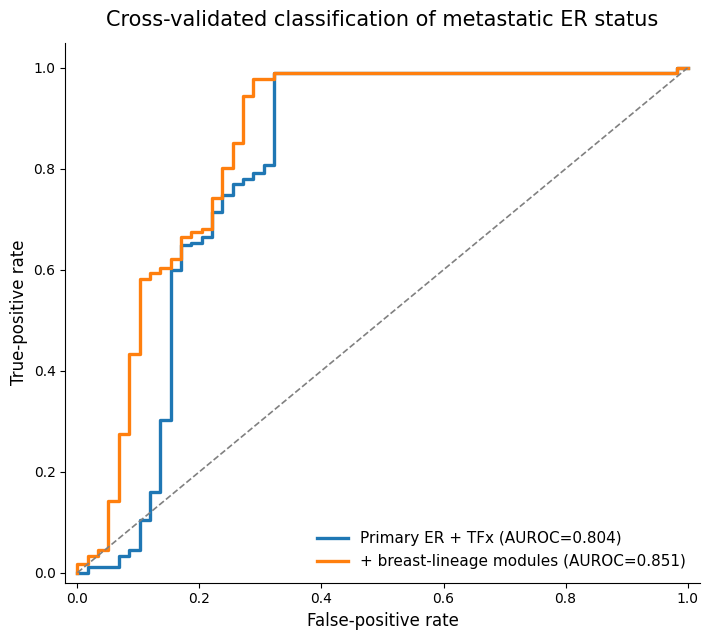

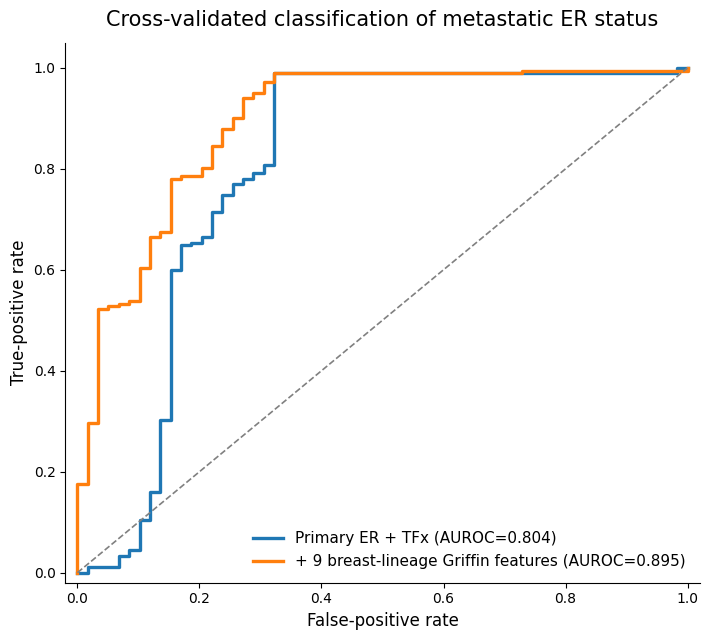

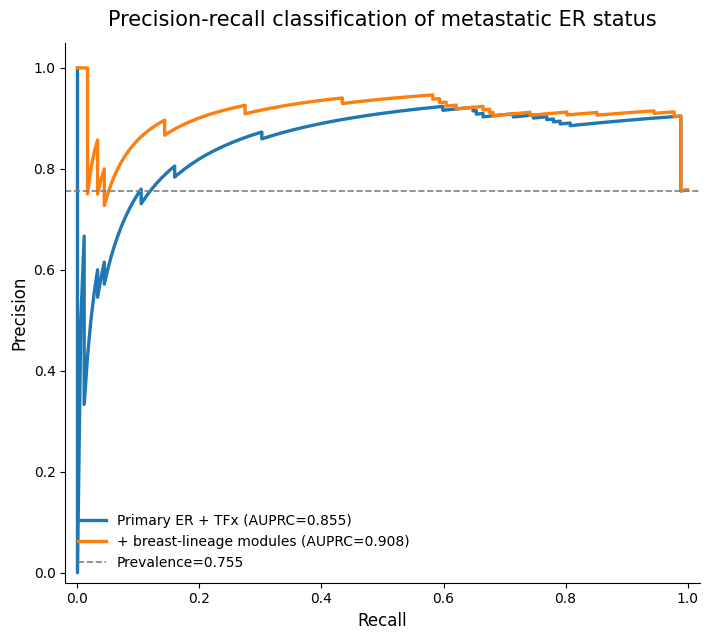


Saved outputs
-------------
/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/Griffin/Downstream/AURORA_Griffin_Metastatic_ER_ROC/AURORA_Griffin_Metastatic_ER_ROC_Cohort.csv
/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/Griffin/Downstream/AURORA_Griffin_Metastatic_ER_ROC/AURORA_Griffin_Metastatic_ER_ROC_Metrics.csv
/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/Griffin/Downstream/AURORA_Griffin_Metastatic_ER_ROC/AURORA_Griffin_Metastatic_ER_ROC_Paired_Deltas.csv
/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/Griffin/Downstream/AURORA_Griffin_Metastatic_ER_ROC/AURORA_Griffin_Metastatic_ER_ROC_OOF_Predictions.csv
/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/Griffin/Downstream/AURORA_Griffin_Metastatic_ER_ROC/AURORA_Griffin_Metastatic_ER_ROC_Hyperparameters.csv
/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/Griffin/Downstream/AURORA_Griffin_Metastatic_ER_ROC/AURORA_Griffin_Metastatic_ER_ROC_Subgroups.csv
/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AU

In [3]:
"""
AURORA Griffin: cross-validated metastatic ER classification
=============================================================

Primary question
----------------
Does a coordinated ESR1/FOXA1/GATA3 cfDNA nucleosome signal add information
about earliest metastatic-diagnosis ER phenotype beyond historical primary ER
status and plasma tumor fraction?

Outcome
-------
Metastatic ER status is derived directly from clinical Category == "Met_Diagnosis"
records. Records are searched chronologically, blank or Unknown ER values are
skipped, and the earliest informative Positive/Negative ER result is selected.
If no informative metastatic ER result exists, status remains Unknown. Patient
588-6 is retained as metastatic ER-positive according to the final curated rule.

Predictive models
-----------------
1. TFx only
2. Primary ER + TFx                                                           [baseline]
3. Primary ER + TFx + 3 breast-lineage modules (Average across each features) [main expanded model]
4. Primary ER + TFx + 9 TFBS-specific Griffin values                          [historical sensitivity]

The three modules are created separately for mean coverage, central coverage,
and amplitude. Within each training fold, ESR1, FOXA1, and GATA3 are median-
imputed, standardized, averaged, and the average is standardized again.

Validation
----------
Repeated stratified cross-validation with a prespecified classifier:
- 5 outer folds x 10 repeats
- elastic-net logistic regression
- all imputation, scaling, and module construction occur in training data only
- each patient receives one out-of-fold prediction per repeat; the 10 predictions are averaged
- patient-level bootstrap confidence intervals and paired model differences

This is internal validation, not external clinical validation. A high overall
AUROC does not prove prediction of receptor conversion because most primary
and metastatic ER records are concordant.

Required packages
-----------------
pandas, numpy, scikit-learn, matplotlib, scipy
"""

# %%
# ============================================================
# 1. Imports
# ============================================================

from __future__ import annotations

import json
import re
import warnings
from collections import Counter
from pathlib import Path
from typing import Dict, Iterable, List, Mapping, Sequence, Tuple

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.special import expit, logit
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    average_precision_score,
    brier_score_loss,
    precision_recall_curve,
    roc_auc_score,
    roc_curve,
)
from sklearn.model_selection import (
    GridSearchCV,
    RepeatedStratifiedKFold,
    StratifiedKFold,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)

# %%
# ============================================================
# 2. USER SETTINGS — edit this section
# ============================================================

CLINICAL_PATH = Path(
    "/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/Clinical_data/AUP_ClinicalData_20260609.xlsx/"
)

PRIMARY_METASHEET_PATH = Path(
    "/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/Clinical_data/"
    "Metasheet_Analysis.with_Histology_Receptor_status.First_Primary.xlsx"
)

GRIFFIN_PATH = Path(
    "/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/Griffin/griffin_nucleosome_profiling/"
    "Griffin_22TF_GC_corrected_summary_by_module.xlsx"
)

OUTPUT_DIR = Path(
    "/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/Griffin/Downstream/"
    "AURORA_Griffin_Metastatic_ER_ROC"
)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Clinical worksheet containing patient_id, Category, receptor records, and
# Days_From_Primary_Diagnosis. Set to None to auto-detect.
CLINICAL_SHEET: str | None = None

TARGET_TFBS = ["ESR1", "FOXA1", "GATA3"]
GRIFFIN_FEATURES = ["mean_coverage", "central_coverage", "amplitude"]

OUTER_SPLITS = 5
OUTER_REPEATS = 10
INNER_SPLITS = 4  # used only when USE_NESTED_TUNING=True
USE_NESTED_TUNING = False
FIXED_LOGISTIC_C = 1.0
FIXED_L1_RATIO = 0.0  # ridge logistic regression
RANDOM_SEED = 20260731
BOOTSTRAP_ITERATIONS = 2000

LOGISTIC_GRID = {
    "model__C": [0.01, 0.1, 1.0, 10.0],
    "model__l1_ratio": [0.0, 0.5, 1.0],
}

MODEL_ORDER = [
    "TFx only",
    "Primary ER + TFx",
    "Primary ER + TFx + breast-lineage modules",
    "Primary ER + TFx + 9 Griffin features",
]

MODEL_TYPES: Mapping[str, str] = {
    "TFx only": "tfx_only",
    "Primary ER + TFx": "baseline",
    "Primary ER + TFx + breast-lineage modules": "module",
    "Primary ER + TFx + 9 Griffin features": "nine_feature",
}

# Main comparison follows the user's requested combined breast-lineage module.
MAIN_BASELINE_MODEL = "Primary ER + TFx"
MAIN_EXPANDED_MODEL = "Primary ER + TFx + breast-lineage modules"

# Historical sensitivity reproduces the earlier nine-feature framing.
HISTORICAL_EXPANDED_MODEL = "Primary ER + TFx + 9 Griffin features"

# Output paths
COHORT_CSV = OUTPUT_DIR / "AURORA_Griffin_Metastatic_ER_ROC_Cohort.csv"
METRICS_CSV = OUTPUT_DIR / "AURORA_Griffin_Metastatic_ER_ROC_Metrics.csv"
DELTAS_CSV = OUTPUT_DIR / "AURORA_Griffin_Metastatic_ER_ROC_Paired_Deltas.csv"
PREDICTIONS_CSV = OUTPUT_DIR / "AURORA_Griffin_Metastatic_ER_ROC_OOF_Predictions.csv"
HYPERPARAMETERS_CSV = OUTPUT_DIR / "AURORA_Griffin_Metastatic_ER_ROC_Hyperparameters.csv"
SUBGROUP_CSV = OUTPUT_DIR / "AURORA_Griffin_Metastatic_ER_ROC_Subgroups.csv"
CONCORDANCE_CSV = OUTPUT_DIR / "AURORA_Griffin_ER_Concordance.csv"
METHODS_CSV = OUTPUT_DIR / "AURORA_Griffin_Metastatic_ER_ROC_Methods.csv"
RUN_INFO_JSON = OUTPUT_DIR / "AURORA_Griffin_Metastatic_ER_ROC_Run_Info.json"

MAIN_ROC_PNG = OUTPUT_DIR / "AURORA_Griffin_Metastatic_ER_ROC_Module.png"
MAIN_ROC_PDF = OUTPUT_DIR / "AURORA_Griffin_Metastatic_ER_ROC_Module.pdf"
HIST_ROC_PNG = OUTPUT_DIR / "AURORA_Griffin_Metastatic_ER_ROC_9Feature_Sensitivity.png"
HIST_ROC_PDF = OUTPUT_DIR / "AURORA_Griffin_Metastatic_ER_ROC_9Feature_Sensitivity.pdf"
PR_PNG = OUTPUT_DIR / "AURORA_Griffin_Metastatic_ER_PR_Module.png"
PR_PDF = OUTPUT_DIR / "AURORA_Griffin_Metastatic_ER_PR_Module.pdf"


# %%
# ============================================================
# 3. Utility functions
# ============================================================


def require_file(path: Path, label: str) -> None:
    if not path.is_file():
        raise FileNotFoundError(f"{label} not found: {path}")


def normalize_patient_id(value: object) -> str:
    if pd.isna(value):
        return ""
    return re.sub(r"\.0$", "", str(value).strip())


def normalize_sample(value: object) -> str:
    if pd.isna(value):
        return ""
    return re.sub(r"^AUP-", "", str(value).strip())


def nb_number(sample: object) -> int:
    match = re.search(r"-NB(\d+)$", str(sample))
    return int(match.group(1)) if match else 10**9


def normalize_status(value: object) -> str:
    if pd.isna(value):
        return "Unknown"
    text = str(value).strip().lower()
    if text in {"positive", "pos", "+", "1", "yes", "true"}:
        return "Positive"
    if text in {"negative", "neg", "-", "0", "no", "false"}:
        return "Negative"
    return "Unknown"


def find_clinical_sheet(path: Path) -> str:
    required = {
        "patient_id",
        "Category",
        "Days_From_Primary_Diagnosis",
        "ER_Status",
    }
    workbook = pd.ExcelFile(path)
    for sheet_name in workbook.sheet_names:
        columns = set(pd.read_excel(path, sheet_name=sheet_name, nrows=0).columns)
        if required.issubset(columns):
            return sheet_name
    raise ValueError(
        f"No worksheet in {path} contains required columns: {sorted(required)}"
    )


def safe_auroc(y: np.ndarray, p: np.ndarray) -> float:
    return float(roc_auc_score(y, p)) if np.unique(y).size == 2 else np.nan


def safe_auprc(y: np.ndarray, p: np.ndarray) -> float:
    return float(average_precision_score(y, p)) if np.unique(y).size == 2 else np.nan


def negative_class_auprc(y: np.ndarray, p: np.ndarray) -> float:
    return safe_auprc(1 - y, 1 - p)


def bootstrap_metric_intervals(
    y: np.ndarray,
    p: np.ndarray,
    iterations: int,
    seed: int,
) -> Dict[str, float]:
    rng = np.random.default_rng(seed)
    n = len(y)
    values = {
        "AUROC": [],
        "AUPRC_ER_positive": [],
        "AUPRC_ER_negative": [],
        "Brier": [],
    }

    for _ in range(iterations):
        index = rng.integers(0, n, n)
        yb = y[index]
        pb = p[index]
        if np.unique(yb).size < 2:
            continue
        values["AUROC"].append(roc_auc_score(yb, pb))
        values["AUPRC_ER_positive"].append(average_precision_score(yb, pb))
        values["AUPRC_ER_negative"].append(average_precision_score(1 - yb, 1 - pb))
        values["Brier"].append(brier_score_loss(yb, pb))

    output: Dict[str, float] = {}
    for metric, metric_values in values.items():
        array = np.asarray(metric_values, dtype=float)
        output[f"{metric}_CI_low"] = float(np.quantile(array, 0.025))
        output[f"{metric}_CI_high"] = float(np.quantile(array, 0.975))
    return output


def paired_bootstrap_delta(
    y: np.ndarray,
    p_expanded: np.ndarray,
    p_baseline: np.ndarray,
    iterations: int,
    seed: int,
) -> Dict[str, float]:
    rng = np.random.default_rng(seed)
    n = len(y)
    deltas: Dict[str, List[float]] = {
        "Delta_AUROC": [],
        "Delta_AUPRC_ER_positive": [],
        "Delta_AUPRC_ER_negative": [],
        "Delta_Brier": [],
    }

    for _ in range(iterations):
        index = rng.integers(0, n, n)
        yb = y[index]
        if np.unique(yb).size < 2:
            continue
        pe = p_expanded[index]
        pb = p_baseline[index]
        deltas["Delta_AUROC"].append(
            roc_auc_score(yb, pe) - roc_auc_score(yb, pb)
        )
        deltas["Delta_AUPRC_ER_positive"].append(
            average_precision_score(yb, pe) - average_precision_score(yb, pb)
        )
        deltas["Delta_AUPRC_ER_negative"].append(
            average_precision_score(1 - yb, 1 - pe)
            - average_precision_score(1 - yb, 1 - pb)
        )
        # Lower Brier is better, so positive Delta_Brier indicates improvement.
        deltas["Delta_Brier"].append(
            brier_score_loss(yb, pb) - brier_score_loss(yb, pe)
        )

    result: Dict[str, float] = {}
    for metric, metric_values in deltas.items():
        array = np.asarray(metric_values, dtype=float)
        observed = {
            "Delta_AUROC": safe_auroc(y, p_expanded) - safe_auroc(y, p_baseline),
            "Delta_AUPRC_ER_positive": safe_auprc(y, p_expanded)
            - safe_auprc(y, p_baseline),
            "Delta_AUPRC_ER_negative": negative_class_auprc(y, p_expanded)
            - negative_class_auprc(y, p_baseline),
            "Delta_Brier": brier_score_loss(y, p_baseline)
            - brier_score_loss(y, p_expanded),
        }[metric]
        result[metric] = float(observed)
        result[f"{metric}_CI_low"] = float(np.quantile(array, 0.025))
        result[f"{metric}_CI_high"] = float(np.quantile(array, 0.975))
        # Two-sided finite-bootstrap tail probability around zero.
        result[f"{metric}_P_bootstrap"] = float(
            min(1.0, 2.0 * min(np.mean(array <= 0), np.mean(array >= 0)))
        )
    return result


# %%
# ============================================================
# 4. Fold-safe feature transformer
# ============================================================


class GriffinPredictorTransformer(BaseEstimator, TransformerMixin):
    """Create model-specific predictors using training-fold parameters only."""

    def __init__(
        self,
        model_type: str,
        raw_griffin_columns: Sequence[str],
        module_groups: Mapping[str, Sequence[str]],
    ) -> None:
        self.model_type = model_type
        self.raw_griffin_columns = raw_griffin_columns
        self.module_groups = module_groups

    def fit(self, x: pd.DataFrame, y=None):
        frame = pd.DataFrame(x).copy()
        self.raw_medians_: Dict[str, float] = {}
        self.raw_means_: Dict[str, float] = {}
        self.raw_sds_: Dict[str, float] = {}
        self.module_means_: Dict[str, float] = {}
        self.module_sds_: Dict[str, float] = {}

        if self.model_type in {"module", "nine_feature"}:
            for column in self.raw_griffin_columns:
                values = pd.to_numeric(frame[column], errors="coerce")
                median = float(values.median())
                if not np.isfinite(median):
                    median = 0.0
                filled = values.fillna(median)
                mean = float(filled.mean())
                sd = float(filled.std(ddof=0))
                if not np.isfinite(sd) or sd <= 0:
                    sd = 1.0
                self.raw_medians_[column] = median
                self.raw_means_[column] = mean
                self.raw_sds_[column] = sd

        if self.model_type == "module":
            for module_name, columns in self.module_groups.items():
                components = []
                for column in columns:
                    values = pd.to_numeric(frame[column], errors="coerce")
                    filled = values.fillna(self.raw_medians_[column])
                    components.append(
                        ((filled - self.raw_means_[column]) / self.raw_sds_[column])
                        .to_numpy(dtype=float)
                    )
                module_raw = np.mean(np.column_stack(components), axis=1)
                module_mean = float(np.mean(module_raw))
                module_sd = float(np.std(module_raw, ddof=0))
                if not np.isfinite(module_sd) or module_sd <= 0:
                    module_sd = 1.0
                self.module_means_[module_name] = module_mean
                self.module_sds_[module_name] = module_sd
        return self

    def transform(self, x: pd.DataFrame) -> np.ndarray:
        frame = pd.DataFrame(x).copy()
        primary_er = pd.to_numeric(frame["primary_er_binary"], errors="coerce")
        tfx = pd.to_numeric(frame["tumor_fraction_per1pct"], errors="coerce")
        primary_er = primary_er.fillna(float(primary_er.median()))
        tfx = tfx.fillna(float(tfx.median()))

        if self.model_type == "tfx_only":
            return tfx.to_numpy(dtype=float).reshape(-1, 1)

        if self.model_type == "baseline":
            return np.column_stack(
                [primary_er.to_numpy(dtype=float), tfx.to_numpy(dtype=float)]
            )

        if self.model_type == "nine_feature":
            columns = [primary_er.to_numpy(dtype=float), tfx.to_numpy(dtype=float)]
            for column in self.raw_griffin_columns:
                values = pd.to_numeric(frame[column], errors="coerce")
                values = values.fillna(self.raw_medians_[column])
                columns.append(values.to_numpy(dtype=float))
            return np.column_stack(columns)

        if self.model_type == "module":
            columns = [primary_er.to_numpy(dtype=float), tfx.to_numpy(dtype=float)]
            for module_name, raw_columns in self.module_groups.items():
                components = []
                for column in raw_columns:
                    values = pd.to_numeric(frame[column], errors="coerce")
                    values = values.fillna(self.raw_medians_[column])
                    components.append(
                        ((values - self.raw_means_[column]) / self.raw_sds_[column])
                        .to_numpy(dtype=float)
                    )
                module_raw = np.mean(np.column_stack(components), axis=1)
                module_z = (
                    module_raw - self.module_means_[module_name]
                ) / self.module_sds_[module_name]
                columns.append(module_z)
            return np.column_stack(columns)

        raise ValueError(f"Unsupported model_type: {self.model_type}")


# %%
# ============================================================
# 5. Build the 177-patient receptor-matched first-draw cohort
# ============================================================

for path, label in [
    (CLINICAL_PATH, "Clinical workbook"),
    (PRIMARY_METASHEET_PATH, "Primary receptor metasheet"),
    (GRIFFIN_PATH, "Griffin workbook"),
]:
    require_file(path, label)

clinical_sheet = CLINICAL_SHEET or find_clinical_sheet(CLINICAL_PATH)
clinical = pd.read_excel(CLINICAL_PATH, sheet_name=clinical_sheet)
primary_meta = pd.read_excel(PRIMARY_METASHEET_PATH)
griffin_long = pd.read_excel(GRIFFIN_PATH, sheet_name="All_TFBS_Long")

required_primary = {
    "Collaborator_sample_id",
    "Patient_id",
    "ER_Status",
    "Tumor_Fraction",
}
missing_primary = required_primary - set(primary_meta.columns)
if missing_primary:
    raise ValueError(f"Primary metasheet missing: {sorted(missing_primary)}")

primary_meta = primary_meta.copy()
primary_meta["patient_id"] = primary_meta["Patient_id"].map(normalize_patient_id)
primary_meta["sample"] = primary_meta["Collaborator_sample_id"].map(normalize_sample)
primary_meta["NB_number"] = primary_meta["sample"].map(nb_number)
primary_meta["primary_ER"] = primary_meta["ER_Status"].map(normalize_status)
primary_meta["tumor_fraction"] = pd.to_numeric(
    primary_meta["Tumor_Fraction"], errors="coerce"
)
primary_meta["tumor_fraction_per1pct"] = primary_meta["tumor_fraction"] * 100.0

first_draw = (
    primary_meta.sort_values(["patient_id", "NB_number", "sample"])
    .drop_duplicates("patient_id", keep="first")
    .copy()
)

# Derive earliest metastatic-diagnosis ER directly from clinical records.
clinical = clinical.copy()
clinical["patient_id_norm"] = clinical["patient_id"].map(normalize_patient_id)
clinical["day_numeric"] = pd.to_numeric(
    clinical["Days_From_Primary_Diagnosis"], errors="coerce"
)
met_records = clinical[
    clinical["Category"].eq("Met_Diagnosis")
    & clinical["patient_id_norm"].isin(set(first_draw["patient_id"]))
].copy()

met_rows: List[Dict[str, object]] = []
for patient_id, patient_rows in met_records.groupby("patient_id_norm", sort=False):
    # Sort all metastatic-diagnosis records chronologically.
    patient_rows = patient_rows.sort_values(
        "day_numeric",
        na_position="last",
    ).copy()

    # Normalize ER status and skip blank/Unknown rows.
    patient_rows["ER_normalized"] = patient_rows[
        "ER_Status"
    ].map(normalize_status)

    informative_rows = patient_rows[
        patient_rows["ER_normalized"].isin(["Positive", "Negative"])
    ].copy()

    earliest_day = patient_rows["day_numeric"].min()

    if informative_rows.empty:
        metastatic_er = "Unknown"
        selected_met_er_day = np.nan
        selected_met_er_site = np.nan
    else:
        # Use the earliest informative metastatic ER record.
        selected_row = informative_rows.iloc[0]
        metastatic_er = selected_row["ER_normalized"]
        selected_met_er_day = selected_row["day_numeric"]
        selected_met_er_site = selected_row.get("Tissue_Site", np.nan)

    # Final agreed curated assignment: 588-6 is concordant ER-positive.
    if patient_id == "588-6":
        metastatic_er = "Positive"

    met_rows.append(
        {
            "patient_id": patient_id,
            "metastatic_ER": metastatic_er,
            "earliest_met_diagnosis_day": earliest_day,
            "selected_met_ER_day": selected_met_er_day,
            "selected_met_ER_site": selected_met_er_site,
            "informative_met_ER_record_count": int(len(informative_rows)),
        }
    )

metastatic_er_table = pd.DataFrame(met_rows)
first_draw = first_draw.merge(
    metastatic_er_table,
    on="patient_id",
    how="left",
    validate="one_to_one",
)
first_draw["metastatic_ER"] = first_draw["metastatic_ER"].fillna("Unknown")
first_draw["primary_er_binary"] = first_draw["primary_ER"].map(
    {"Negative": 0, "Positive": 1}
)
first_draw["metastatic_er_binary"] = first_draw["metastatic_ER"].map(
    {"Negative": 0, "Positive": 1}
)

# Pivot the nine raw breast-lineage Griffin values.
griffin_long = griffin_long.copy()
griffin_long["sample"] = griffin_long["sample"].map(normalize_sample)
griffin_breast = griffin_long[
    griffin_long["site_name"].isin(TARGET_TFBS)
].copy()

wide_parts: List[pd.DataFrame] = []
for feature in GRIFFIN_FEATURES:
    part = griffin_breast.pivot(
        index="sample",
        columns="site_name",
        values=feature,
    )
    part = part.rename(
        columns={tfbs: f"{tfbs}_{feature}" for tfbs in part.columns}
    )
    wide_parts.append(part)

wide_griffin = pd.concat(wide_parts, axis=1).reset_index()
analysis_data = first_draw.merge(
    wide_griffin,
    on="sample",
    how="left",
    validate="one_to_one",
)

RAW_GRIFFIN_COLUMNS = [
    f"{tfbs}_{feature}"
    for feature in GRIFFIN_FEATURES
    for tfbs in TARGET_TFBS
]

MODULE_GROUPS: Mapping[str, Sequence[str]] = {
    "Mean coverage": [f"{tfbs}_mean_coverage" for tfbs in TARGET_TFBS],
    "Central coverage": [f"{tfbs}_central_coverage" for tfbs in TARGET_TFBS],
    "Amplitude": [f"{tfbs}_amplitude" for tfbs in TARGET_TFBS],
}

required_for_roc = [
    "primary_er_binary",
    "metastatic_er_binary",
    "tumor_fraction_per1pct",
] + RAW_GRIFFIN_COLUMNS

roc_cohort = (
    analysis_data.dropna(subset=required_for_roc)
    .sort_values("patient_id")
    .reset_index(drop=True)
)

print(
    f"Final receptor-matched ROC cohort: {roc_cohort.shape[0]} patients"
)

roc_cohort["ER_transition"] = (
    roc_cohort["primary_ER"] + " -> " + roc_cohort["metastatic_ER"]
)
roc_cohort["TF_group"] = np.where(
    roc_cohort["tumor_fraction_per1pct"] < 3.0,
    "TFx <3%",
    "TFx >=3%",
)

cohort_columns = [
    "patient_id",
    "sample",
    "primary_ER",
    "metastatic_ER",
    "primary_er_binary",
    "metastatic_er_binary",
    "tumor_fraction",
    "tumor_fraction_per1pct",
    "earliest_met_diagnosis_day",
    "selected_met_ER_day",
    "selected_met_ER_site",
    "informative_met_ER_record_count",
    "ER_transition",
    "TF_group",
] + RAW_GRIFFIN_COLUMNS
roc_cohort[cohort_columns].to_csv(COHORT_CSV, index=False)

concordance = pd.crosstab(
    roc_cohort["primary_ER"],
    roc_cohort["metastatic_ER"],
).reindex(index=["Negative", "Positive"], columns=["Negative", "Positive"], fill_value=0)
concordance.index.name = "Primary_ER"
concordance.to_csv(CONCORDANCE_CSV)

print("\nCohort summary")
print("--------------")
print("Patients:", roc_cohort.shape[0])
print("Metastatic ER+:", int(roc_cohort["metastatic_er_binary"].sum()))
print("Metastatic ER-:", int((1 - roc_cohort["metastatic_er_binary"]).sum()))
print("Primary ER+:", int(roc_cohort["primary_er_binary"].sum()))
print("Primary ER-:", int((1 - roc_cohort["primary_er_binary"]).sum()))
print("TFx <3%:", int((roc_cohort["tumor_fraction_per1pct"] < 3).sum()))

print("\nPrimary/metastatic concordance")
print(concordance.to_string())

er_discordant = roc_cohort[
    roc_cohort["primary_ER"].ne(roc_cohort["metastatic_ER"])
].copy()

er_concordant = roc_cohort[
    roc_cohort["primary_ER"].eq(roc_cohort["metastatic_ER"])
].copy()

print("\nER concordance summary")
print("----------------------")
print("Paired evaluable patients:", len(roc_cohort))
print("ER-concordant patients:", len(er_concordant))
print("ER-discordant patients:", len(er_discordant))

print("\nER transition counts")
print(
    roc_cohort.groupby(
        ["primary_ER", "metastatic_ER"]
    ).size().to_string()
)

print("\nER-discordant patient details")
print(
    er_discordant[
        [
            "patient_id",
            "sample",
            "primary_ER",
            "metastatic_ER",
            "earliest_met_diagnosis_day",
            "selected_met_ER_day",
            "selected_met_ER_site",
            "informative_met_ER_record_count",
        ]
    ]
    .sort_values("patient_id")
    .to_string(index=False)
)

if len(er_discordant) != 21:
    print(
        "WARNING: Expected 21 ER-discordant patients under the final "
        f"curated rule, but found {len(er_discordant)}."
    )


# %%
# ============================================================
# 6. Repeated cross-validation
# ============================================================

X = roc_cohort[
    ["primary_er_binary", "tumor_fraction_per1pct"] + RAW_GRIFFIN_COLUMNS
].copy()
y = roc_cohort["metastatic_er_binary"].astype(int).to_numpy()

outer_cv = RepeatedStratifiedKFold(
    n_splits=OUTER_SPLITS,
    n_repeats=OUTER_REPEATS,
    random_state=RANDOM_SEED,
)
# Materialize once so every model uses identical held-out patients.
outer_splits = list(outer_cv.split(X, y))

prediction_rows: List[pd.DataFrame] = []
metric_rows: List[Dict[str, object]] = []
hyperparameter_rows: List[Dict[str, object]] = []
model_predictions: Dict[str, np.ndarray] = {}

for model_number, model_name in enumerate(MODEL_ORDER):
    model_type = MODEL_TYPES[model_name]
    print(f"\nRunning repeated CV: {model_name}")

    prediction_sum = np.zeros(len(roc_cohort), dtype=float)
    prediction_count = np.zeros(len(roc_cohort), dtype=int)
    selected_parameters: List[Tuple[float, float]] = []

    for fold_number, (train_index, test_index) in enumerate(outer_splits, start=1):
        pipeline = Pipeline(
            steps=[
                (
                    "features",
                    GriffinPredictorTransformer(
                        model_type=model_type,
                        raw_griffin_columns=RAW_GRIFFIN_COLUMNS,
                        module_groups=MODULE_GROUPS,
                    ),
                ),
                ("scaler", StandardScaler()),
                (
                    "model",
                    LogisticRegression(
                        penalty="elasticnet",
                        solver="saga",
                        class_weight="balanced",
                        max_iter=10000,
                        random_state=RANDOM_SEED + fold_number + 1000 * model_number,
                    ),
                ),
            ]
        )

        if USE_NESTED_TUNING:
            inner_cv = StratifiedKFold(
                n_splits=INNER_SPLITS,
                shuffle=True,
                random_state=RANDOM_SEED + fold_number,
            )
            search = GridSearchCV(
                estimator=pipeline,
                param_grid=LOGISTIC_GRID,
                scoring="roc_auc",
                cv=inner_cv,
                n_jobs=-1,
                refit=True,
            )
            search.fit(X.iloc[train_index], y[train_index])
            fitted_model = search.best_estimator_
            best_c = float(search.best_params_["model__C"])
            best_l1 = float(search.best_params_["model__l1_ratio"])
            best_inner_auc = float(search.best_score_)
        else:
            pipeline.set_params(
                model__C=FIXED_LOGISTIC_C,
                model__l1_ratio=FIXED_L1_RATIO,
            )
            fitted_model = pipeline.fit(X.iloc[train_index], y[train_index])
            best_c = FIXED_LOGISTIC_C
            best_l1 = FIXED_L1_RATIO
            best_inner_auc = np.nan

        probability = fitted_model.predict_proba(X.iloc[test_index])[:, 1]
        prediction_sum[test_index] += probability
        prediction_count[test_index] += 1

        selected_parameters.append((best_c, best_l1))
        hyperparameter_rows.append(
            {
                "Model": model_name,
                "Outer_fold_number": fold_number,
                "Best_C": best_c,
                "Best_l1_ratio": best_l1,
                "Best_inner_AUROC": best_inner_auc,
            }
        )

    if not np.all(prediction_count == OUTER_REPEATS):
        raise RuntimeError(
            f"Unexpected prediction counts for {model_name}: "
            f"{np.unique(prediction_count, return_counts=True)}"
        )

    final_probability = prediction_sum / prediction_count
    model_predictions[model_name] = final_probability

    ci = bootstrap_metric_intervals(
        y=y,
        p=final_probability,
        iterations=BOOTSTRAP_ITERATIONS,
        seed=RANDOM_SEED + 100000 + model_number,
    )

    parameter_counts = Counter(selected_parameters)
    metric_rows.append(
        {
            "Model": model_name,
            "N": int(len(y)),
            "Metastatic_ER_positive_N": int(y.sum()),
            "Metastatic_ER_negative_N": int((1 - y).sum()),
            "Metastatic_ER_positive_prevalence": float(y.mean()),
            "AUROC": safe_auroc(y, final_probability),
            "AUPRC_ER_positive": safe_auprc(y, final_probability),
            "AUPRC_ER_negative": negative_class_auprc(y, final_probability),
            "Brier_score": float(brier_score_loss(y, final_probability)),
            "Outer_splits": OUTER_SPLITS,
            "Outer_repeats": OUTER_REPEATS,
            "Inner_splits": INNER_SPLITS if USE_NESTED_TUNING else np.nan,
            "Most_common_hyperparameters": str(parameter_counts.most_common(5)),
            **ci,
        }
    )

    prediction_rows.append(
        pd.DataFrame(
            {
                "patient_id": roc_cohort["patient_id"],
                "sample": roc_cohort["sample"],
                "primary_ER": roc_cohort["primary_ER"],
                "metastatic_ER": roc_cohort["metastatic_ER"],
                "ER_transition": roc_cohort["ER_transition"],
                "TF_group": roc_cohort["TF_group"],
                "tumor_fraction_per1pct": roc_cohort["tumor_fraction_per1pct"],
                "Observed_metastatic_ER_positive": y,
                "Model": model_name,
                "OOF_probability_metastatic_ER_positive": final_probability,
                "Prediction_count": prediction_count,
            }
        )
    )

metrics = pd.DataFrame(metric_rows)
metrics["Model"] = pd.Categorical(metrics["Model"], categories=MODEL_ORDER, ordered=True)
metrics = metrics.sort_values("Model").reset_index(drop=True)
predictions = pd.concat(prediction_rows, ignore_index=True)
hyperparameters = pd.DataFrame(hyperparameter_rows)

metrics.to_csv(METRICS_CSV, index=False)
predictions.to_csv(PREDICTIONS_CSV, index=False)
hyperparameters.to_csv(HYPERPARAMETERS_CSV, index=False)

print("\nCross-validated metrics")
print("-----------------------")
print(
    metrics[
        [
            "Model",
            "N",
            "AUROC",
            "AUROC_CI_low",
            "AUROC_CI_high",
            "AUPRC_ER_positive",
            "AUPRC_ER_negative",
            "Brier_score",
        ]
    ].to_string(index=False)
)


# %%
# ============================================================
# 7. Paired bootstrap improvements
# ============================================================

comparison_specs = [
    (
        "Main module comparison",
        MAIN_EXPANDED_MODEL,
        MAIN_BASELINE_MODEL,
    ),
    (
        "Historical 9-feature sensitivity",
        HISTORICAL_EXPANDED_MODEL,
        MAIN_BASELINE_MODEL,
    ),
]

delta_rows: List[Dict[str, object]] = []
for comparison_number, (label, expanded, baseline) in enumerate(comparison_specs):
    delta = paired_bootstrap_delta(
        y=y,
        p_expanded=model_predictions[expanded],
        p_baseline=model_predictions[baseline],
        iterations=BOOTSTRAP_ITERATIONS,
        seed=RANDOM_SEED + 200000 + comparison_number,
    )
    delta_rows.append(
        {
            "Comparison": label,
            "Expanded_model": expanded,
            "Baseline_model": baseline,
            **delta,
        }
    )

deltas = pd.DataFrame(delta_rows)
deltas.to_csv(DELTAS_CSV, index=False)

print("\nPaired model improvements")
print("-------------------------")
print(deltas.to_string(index=False))


# %%
# ============================================================
# 8. Subgroup performance
# ============================================================

subgroup_rows: List[Dict[str, object]] = []
subgroup_definitions = {
    "All patients": np.ones(len(roc_cohort), dtype=bool),
    "TFx <3%": roc_cohort["tumor_fraction_per1pct"].to_numpy() < 3.0,
    "TFx >=3%": roc_cohort["tumor_fraction_per1pct"].to_numpy() >= 3.0,
    "Primary/metastatic ER discordant": (
        roc_cohort["primary_ER"].to_numpy() != roc_cohort["metastatic_ER"].to_numpy()
    ),
}

for subgroup_name, mask in subgroup_definitions.items():
    subgroup_y = y[mask]
    for model_name in [
        MAIN_BASELINE_MODEL,
        MAIN_EXPANDED_MODEL,
        HISTORICAL_EXPANDED_MODEL,
    ]:
        subgroup_probability = model_predictions[model_name][mask]
        subgroup_rows.append(
            {
                "Subgroup": subgroup_name,
                "Model": model_name,
                "N": int(mask.sum()),
                "Metastatic_ER_positive_N": int(subgroup_y.sum()),
                "Metastatic_ER_negative_N": int((1 - subgroup_y).sum()),
                "AUROC": safe_auroc(subgroup_y, subgroup_probability),
                "AUPRC_ER_positive": safe_auprc(subgroup_y, subgroup_probability),
                "AUPRC_ER_negative": negative_class_auprc(
                    subgroup_y, subgroup_probability
                ),
                "Brier_score": float(
                    brier_score_loss(subgroup_y, subgroup_probability)
                ),
            }
        )

subgroups = pd.DataFrame(subgroup_rows)
subgroups.to_csv(SUBGROUP_CSV, index=False)


# %%
# ============================================================
# 9. ROC and precision-recall plots
# ============================================================


def metric_value(model_name: str, column: str) -> float:
    return float(metrics.loc[metrics["Model"].eq(model_name), column].iloc[0])


def plot_two_model_roc(
    baseline_model: str,
    expanded_model: str,
    expanded_short_label: str,
    title: str,
    png_path: Path,
    pdf_path: Path,
) -> None:
    fig, ax = plt.subplots(figsize=(7.2, 6.5))

    for model_name, label in [
        (
            baseline_model,
            f"Primary ER + TFx (AUROC={metric_value(baseline_model, 'AUROC'):.3f})",
        ),
        (
            expanded_model,
            f"{expanded_short_label} (AUROC={metric_value(expanded_model, 'AUROC'):.3f})",
        ),
    ]:
        fpr, tpr, _ = roc_curve(y, model_predictions[model_name])
        ax.plot(fpr, tpr, linewidth=2.4, label=label)

    ax.plot([0, 1], [0, 1], linestyle="--", linewidth=1.2, color="gray")
    ax.set_xlim(-0.02, 1.02)
    ax.set_ylim(-0.02, 1.05)
    ax.set_xlabel("False-positive rate", fontsize=12)
    ax.set_ylabel("True-positive rate", fontsize=12)
    ax.set_title(title, fontsize=15, pad=12)
    ax.legend(frameon=False, loc="lower right", fontsize=11)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.tick_params(labelsize=10)
    fig.tight_layout()
    fig.savefig(png_path, dpi=400, bbox_inches="tight")
    fig.savefig(pdf_path, bbox_inches="tight")
    plt.show()
    plt.close(fig)


plot_two_model_roc(
    baseline_model=MAIN_BASELINE_MODEL,
    expanded_model=MAIN_EXPANDED_MODEL,
    expanded_short_label="+ breast-lineage modules",
    title="Cross-validated classification of metastatic ER status",
    png_path=MAIN_ROC_PNG,
    pdf_path=MAIN_ROC_PDF,
)

plot_two_model_roc(
    baseline_model=MAIN_BASELINE_MODEL,
    expanded_model=HISTORICAL_EXPANDED_MODEL,
    expanded_short_label="+ 9 breast-lineage Griffin features",
    title="Cross-validated classification of metastatic ER status",
    png_path=HIST_ROC_PNG,
    pdf_path=HIST_ROC_PDF,
)

# Precision-recall figure for the primary module comparison.
fig, ax = plt.subplots(figsize=(7.2, 6.5))
for model_name, label in [
    (
        MAIN_BASELINE_MODEL,
        f"Primary ER + TFx (AUPRC={metric_value(MAIN_BASELINE_MODEL, 'AUPRC_ER_positive'):.3f})",
    ),
    (
        MAIN_EXPANDED_MODEL,
        f"+ breast-lineage modules (AUPRC={metric_value(MAIN_EXPANDED_MODEL, 'AUPRC_ER_positive'):.3f})",
    ),
]:
    precision, recall, _ = precision_recall_curve(y, model_predictions[model_name])
    ax.plot(recall, precision, linewidth=2.4, label=label)
ax.axhline(y.mean(), linestyle="--", linewidth=1.2, color="gray", label=f"Prevalence={y.mean():.3f}")
ax.set_xlim(-0.02, 1.02)
ax.set_ylim(-0.02, 1.05)
ax.set_xlabel("Recall", fontsize=12)
ax.set_ylabel("Precision", fontsize=12)
ax.set_title("Precision-recall classification of metastatic ER status", fontsize=15, pad=12)
ax.legend(frameon=False, loc="lower left", fontsize=10)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
fig.tight_layout()
fig.savefig(PR_PNG, dpi=400, bbox_inches="tight")
fig.savefig(PR_PDF, bbox_inches="tight")
plt.show()
plt.close(fig)


# %%
# ============================================================
# 10. Methods and run information
# ============================================================

methods = pd.DataFrame(
    [
        ["Outcome", "Metastatic ER phenotype derived from clinical Category=Met_Diagnosis records using the earliest informative Positive/Negative ER result after skipping blank/Unknown records; 588-6 is retained as metastatic ER-positive by the final curated rule."],
        ["First cfDNA draw", "Lowest NB number per patient in the primary receptor/tumor-fraction metasheet."],
        ["Primary baseline", "Primary ER status plus tumor_fraction_per1pct."],
        ["tumor_fraction_per1pct", "Tumor_Fraction proportion multiplied by 100; one unit equals one percentage-point tumor-fraction increase."],
        ["Breast-lineage modules", "Three outcomes/predictors: mean coverage, central coverage, and amplitude. Within each training fold, ESR1, FOXA1, and GATA3 are median-imputed, separately z-standardized, averaged, and the average is z-standardized."],
        ["Nine-feature sensitivity", "ESR1, FOXA1, and GATA3 mean coverage, central coverage, and amplitude entered individually (nine predictors)."],
        ["Cross-validation", f"Repeated stratified CV: {OUTER_SPLITS} folds x {OUTER_REPEATS} repeats; identical held-out splits for all models."],
        ["Classifier", f"Prespecified ridge logistic regression with class_weight='balanced', C={FIXED_LOGISTIC_C}. Set USE_NESTED_TUNING=True for optional elastic-net inner tuning."],
        ["Leakage prevention", "Imputation, feature scaling, and module construction are fitted within training data only."],
        ["OOF prediction", "Each patient is held out once per repeat; ten held-out probabilities are averaged into one patient-level probability."],
        ["Uncertainty", f"Patient-level bootstrap with {BOOTSTRAP_ITERATIONS} resamples for 95% confidence intervals and paired model deltas."],
        ["Interpretation", "Internal validation only. Overall performance is strongly influenced by primary/metastatic ER concordance and does not establish prediction of receptor conversion."],
    ],
    columns=["Item", "Definition"],
)
methods.to_csv(METHODS_CSV, index=False)

run_info = {
    "script_version": SCRIPT_VERSION,
    "clinical_path": str(CLINICAL_PATH),
    "clinical_sheet": clinical_sheet,
    "primary_metasheet_path": str(PRIMARY_METASHEET_PATH),
    "griffin_path": str(GRIFFIN_PATH),
    "output_dir": str(OUTPUT_DIR),
    "n_patients": int(len(roc_cohort)),
    "metastatic_er_positive_n": int(y.sum()),
    "metastatic_er_negative_n": int((1 - y).sum()),
    "primary_er_positive_n": int(roc_cohort["primary_er_binary"].sum()),
    "primary_er_negative_n": int((1 - roc_cohort["primary_er_binary"]).sum()),
    "outer_splits": OUTER_SPLITS,
    "outer_repeats": OUTER_REPEATS,
    "inner_splits": INNER_SPLITS if USE_NESTED_TUNING else None,
    "use_nested_tuning": USE_NESTED_TUNING,
    "fixed_logistic_C": FIXED_LOGISTIC_C,
    "random_seed": RANDOM_SEED,
    "bootstrap_iterations": BOOTSTRAP_ITERATIONS,
    "models": MODEL_ORDER,
}
RUN_INFO_JSON.write_text(json.dumps(run_info, indent=2))

print("\nSaved outputs")
print("-------------")
for path in [
    COHORT_CSV,
    METRICS_CSV,
    DELTAS_CSV,
    PREDICTIONS_CSV,
    HYPERPARAMETERS_CSV,
    SUBGROUP_CSV,
    CONCORDANCE_CSV,
    METHODS_CSV,
    RUN_INFO_JSON,
    MAIN_ROC_PNG,
    MAIN_ROC_PDF,
    HIST_ROC_PNG,
    HIST_ROC_PDF,
    PR_PNG,
    PR_PDF,
]:
    print(path)